# NYC Safety & Traffic Analysis

## Data Engineering and Visualization — Milestone 1

### Project Overview

This project analyzes the relationship between two NYC Open Data datasets from different domains:

1. **DOB Safety Violations** — Housing & Development
2. **SIRTA Data** — Transportation

The goal is to explore, clean, transform, and integrate the two datasets to investigate meaningful relationships between building safety and transportation safety in New York City.

The datasets will be analyzed individually first through exploratory data analysis (EDA) and pre-integration cleaning. They will then be transformed to a common geographic and temporal level and integrated using appropriate attributes.

The final analysis will support the project's research questions, visualizations, and interactive website.

In [ ]:
# ============================================
# 1. Import Required Libraries
# ============================================

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the DOB Safety Violations Dataset

The first dataset is **DOB Safety Violations**, from the Housing & Development domain.

It contains records related to safety violations issued by the New York City Department of Buildings.

Dataset ID: `855j-jady`

We will first load the dataset without making assumptions about its columns or data quality. The structure, data types, missing values, duplicates, geographic fields, and temporal fields will be examined in the following steps before any cleaning is performed.

In [ ]:
# ============================================
# 2. Load DOB Safety Violations Dataset
# ============================================

housing_id = "855j-jady"

housing_url = (
    f"https://data.cityofnewyork.us/resource/{housing_id}.csv"
    "?$limit=100000"
)

try:
    df_housing = pd.read_csv(
        housing_url,
        low_memory=False
    )

    print("DOB Safety Violations dataset loaded successfully.")
    print(f"Rows: {df_housing.shape[0]:,}")
    print(f"Columns: {df_housing.shape[1]:,}")

except Exception as e:
    print("The NYC Open Data API could not be reached.")
    print("Error:", e)

# Display the first 5 rows
display(df_housing.head())



DOB Safety Violations dataset loaded successfully.
Rows: 100,000
Columns: 24


,bin,violation_issue_date,violation_number,violation_type,violation_remarks,violation_status,device_number,device_type,cycle_end_date,borough,block,lot,house_number,street,city,state,zip,latitude,longitude,community_board,council_district,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,5108512,2026-11-06T00:00:00.000,NOD-FTF-EN-2026LL97320-202612-0003110,FTF-EN-LL97320,FAILURE TO FILE AN ANNUAL BUILDINGS EMISSIONS ...,Active,NaN,GHG Emissions - LL97,NaN,Staten Island,2380.0,7501.0,85,COUNTRY DRIVE SOUTH,New York,New York,10314.0,40.587861,-74.164895,502.0,51.0,5.023808e+09,27706.0,New Springville-Willowbrook-Bulls Head-Travis
1,5116265,2026-11-06T00:00:00.000,NOD-FTF-EN-2026LL97320-202612-0002488,FTF-EN-LL97320,FAILURE TO FILE AN ANNUAL BUILDINGS EMISSIONS ...,Active,NaN,GHG Emissions - LL97,NaN,Staten Island,230.0,7502.0,29,ARCADIA PLACE,New York,New York,10310.0,40.628009,-74.123276,501.0,49.0,5.002308e+09,141.0,Port Richmond
2,5126755,2026-11-06T00:00:00.000,NOD-FTF-EN-2026LL97320-202612-0003334,FTF-EN-LL97320,FAILURE TO FILE AN ANNUAL BUILDINGS EMISSIONS ...,Active,NaN,GHG Emissions - LL97,NaN,Staten Island,2410.0,7501.0,84,SATURN LANE,New York,New York,10314.0,40.582895,-74.157430,502.0,51.0,5.024108e+09,27702.0,New Springville-Willowbrook-Bulls Head-Travis
3,5123459,2026-11-06T00:00:00.000,NOD-FTF-EN-2026LL97320-202612-0002298,FTF-EN-LL97320,FAILURE TO FILE AN ANNUAL BUILDINGS EMISSIONS ...,Active,NaN,GHG Emissions - LL97,NaN,Staten Island,7041.0,7501.0,621,CORRELL AVENUE,New York,New York,10309.0,40.546019,-74.213456,503.0,51.0,5.070418e+09,20805.0,Arden Heights-Rossville
4,5122106,2026-11-06T00:00:00.000,NOD-FTF-EN-2026LL97320-202612-0004094,FTF-EN-LL97320,FAILURE TO FILE AN ANNUAL BUILDINGS EMISSIONS ...,Active,NaN,GHG Emissions - LL97,NaN,Staten Island,3173.0,7501.0,122,GATEWAY DRIVE,New York,New York,10304.0,40.603089,-74.087330,502.0,50.0,5.031738e+09,50.0,Grasmere-Arrochar-South Beach-Dongan Hills


In [ ]:
# Display the column names
print("DOB Safety Violations columns:")
for i, column in enumerate(df_housing.columns, start=1):
    print(f"{i}. {column}")

DOB Safety Violations columns:
1. bin
2. violation_issue_date
3. violation_number
4. violation_type
5. violation_remarks
6. violation_status
7. device_number
8. device_type
9. cycle_end_date
10. borough
11. block
12. lot
13. house_number
14. street
15. city
16. state
17. zip
18. latitude
19. longitude
20. community_board
21. council_district
22. bbl
23. census_tract_2020_
24. neighborhood_tabulation_area_nta_2020_


## 3. Initial Inspection — DOB Safety Violations

Before performing any cleaning, we inspect the dataset's structure, data types, missing values, duplicate records, date range, and geographic values.

This allows us to identify data-quality issues before making any transformations or assumptions.

In [ ]:
# ============================================
# 3.1 Dataset Structure
# ============================================

print("Dataset shape:")
print(f"Rows: {df_housing.shape[0]:,}")
print(f"Columns: {df_housing.shape[1]}")

print("\nData types:")
display(df_housing.dtypes)

Dataset shape:
Rows: 100,000
Columns: 24

Data types:


,0
bin,int64
violation_issue_date,object
violation_number,object
violation_type,object
violation_remarks,object
violation_status,object
device_number,object
device_type,object
cycle_end_date,object
borough,object


In [ ]:
# ============================================
# 3.2 Missing Values
# ============================================

missing_housing = pd.DataFrame({
    "missing_count": df_housing.isna().sum(),
    "missing_percentage": (df_housing.isna().mean() * 100).round(2)
})

missing_housing = missing_housing.sort_values(
    "missing_count",
    ascending=False
)

display(missing_housing)

,missing_count,missing_percentage
device_number,78498,78.50
cycle_end_date,52163,52.16
violation_remarks,12233,12.23
bbl,673,0.67
neighborhood_tabulation_area_nta_2020_,249,0.25
council_district,249,0.25
community_board,249,0.25
longitude,249,0.25
latitude,249,0.25
census_tract_2020_,249,0.25


In [ ]:
# ============================================
# 3.3 Duplicate Records
# ============================================

duplicate_count = df_housing.duplicated().sum()

print(f"Number of completely duplicated rows: {duplicate_count:,}")
print(
    f"Percentage of duplicated rows: "
    f"{(duplicate_count / len(df_housing) * 100):.2f}%"
)

Number of completely duplicated rows: 0
Percentage of duplicated rows: 0.00%


In [ ]:
# ============================================
# 3.4 Date Range
# ============================================

housing_dates = pd.to_datetime(
    df_housing["violation_issue_date"],
    errors="coerce"
)

print("Violation issue date range:")
print(f"Earliest date: {housing_dates.min()}")
print(f"Latest date:   {housing_dates.max()}")

print("\nInvalid/unparseable dates:")
print(housing_dates.isna().sum())

Violation issue date range:
Earliest date: 2025-10-31 00:00:00
Latest date:   2026-11-06 00:00:00

Invalid/unparseable dates:
0


In [ ]:
# ============================================
# 3.5 Borough Values
# ============================================

print("Unique borough values:")
print(df_housing["borough"].value_counts(dropna=False))

Unique borough values:
borough
Brooklyn         30039
Manhattan        24316
Queens           18883
Bronx            14866
Staten Island    11796
NaN                100
Name: count, dtype: int64


## 4. Define the Analysis Period

The initial API download returned 100,000 records, but the returned records covered a period from October 2025 to November 2026.

Because the final project integrates the datasets at the borough-year level for the period 2022–2025, we will retrieve DOB Safety Violations records within the 2022–2025 period before performing the main cleaning and analysis.

This ensures that the housing and transportation datasets can later be compared over the same temporal range.

In [ ]:
# ============================================
# 4.1 Load DOB Safety Violations for 2022-2025
# ============================================

from urllib.parse import urlencode

housing_id = "855j-jady"

api_url = f"https://data.cityofnewyork.us/resource/{housing_id}.csv"

params = {
    "$limit": 1000000,
    "$where": (
        "violation_issue_date >= '2022-01-01T00:00:00' "
        "AND violation_issue_date < '2026-01-01T00:00:00'"
    )
}

housing_url = api_url + "?" + urlencode(params)

df_housing = pd.read_csv(
    housing_url,
    low_memory=False
)

print("DOB Safety Violations dataset for 2022-2025 loaded successfully.")
print(f"Rows: {df_housing.shape[0]:,}")
print(f"Columns: {df_housing.shape[1]:,}")

DOB Safety Violations dataset for 2022-2025 loaded successfully.
Rows: 519,337
Columns: 24


In [ ]:
# ============================================
# 4.2 Verify the Actual Date Range
# ============================================

df_housing["violation_issue_date"] = pd.to_datetime(
    df_housing["violation_issue_date"],
    errors="coerce"
)

print("Actual date range:")
print(f"Earliest: {df_housing['violation_issue_date'].min()}")
print(f"Latest:   {df_housing['violation_issue_date'].max()}")

Actual date range:
Earliest: 2022-01-03 00:00:00
Latest:   2025-12-19 00:00:00


In [ ]:
# ============================================
# 4.3 Records per Year
# ============================================

housing_year_counts = (
    df_housing["violation_issue_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

display(housing_year_counts)

,count
violation_issue_date,
2022,18840
2023,283139
2024,68289
2025,149069


## 5. DOB Safety Violations — Dataset Overview

The first dataset selected for this project is the **DOB Safety Violations** dataset from the Housing & Development domain.

**NYC Open Data Dataset ID:** `855j-jady`

The dataset contains records of safety violations associated with buildings in New York City. Relevant attributes for this project include:

- `borough` — geographic identifier used for integration
- `violation_issue_date` — temporal attribute used to derive year
- `violation_number` — violation identifier
- `violation_type` — type/category of violation
- `violation_status` — status of the violation
- `bin` — building identification number
- `latitude` and `longitude` — geographic coordinates
- `block`, `lot`, and `bbl` — additional property/location identifiers

For the main analysis, records with violation issue dates from **2022 through 2025** are used. This gives us a common temporal period that can later be aligned with the transportation dataset.

The filtered dataset contains **519,337 records and 24 columns**.

### Initial temporal distribution

| Year | Violation Records |
|------|------------------:|
| 2022 | 18,840 |
| 2023 | 283,139 |
| 2024 | 68,289 |
| 2025 | 149,069 |

The large variation in records between years will be investigated during exploratory data analysis before drawing any conclusions.

In [ ]:
# ============================================
# 6.1 Missing Values — Final DOB Dataset
# ============================================

missing_housing = pd.DataFrame({
    "missing_count": df_housing.isna().sum(),
    "missing_percentage": (df_housing.isna().mean() * 100).round(2)
})

missing_housing = missing_housing.sort_values(
    "missing_count",
    ascending=False
)

display(missing_housing)

,missing_count,missing_percentage
device_number,335307,64.56
cycle_end_date,133456,25.70
violation_remarks,40627,7.82
bbl,3553,0.68
neighborhood_tabulation_area_nta_2020_,1482,0.29
council_district,1482,0.29
community_board,1482,0.29
longitude,1482,0.29
latitude,1482,0.29
census_tract_2020_,1482,0.29


In [ ]:
# ============================================
# 6.2 Duplicate Records — Final DOB Dataset
# ============================================

duplicate_count = df_housing.duplicated().sum()

print(f"Completely duplicated rows: {duplicate_count:,}")
print(
    f"Percentage of duplicated rows: "
    f"{(duplicate_count / len(df_housing) * 100):.2f}%"
)

Completely duplicated rows: 0
Percentage of duplicated rows: 0.00%


In [ ]:
# ============================================
# 6.3 Borough Distribution
# ============================================

borough_counts = (
    df_housing["borough"]
    .value_counts(dropna=False)
)

display(borough_counts)

,count
borough,
Brooklyn,169975
Manhattan,155734
Queens,104147
Bronx,73600
Staten Island,14898
NaN,983


In [ ]:
# ============================================
# 6.4 Violation Types
# ============================================

print("Number of unique violation types:")
print(df_housing["violation_type"].nunique(dropna=True))

print("\nTop 15 violation types:")
display(
    df_housing["violation_type"]
    .value_counts(dropna=False)
    .head(15)
)

Number of unique violation types:
32

Top 15 violation types:


,count
violation_type,
LBLVIO,140064
FTF-PL-PER,89163
FTC-VT-CAT1-CO,69320
FTF-VT-CAT1-CO,38642
FTC-BE-EXT-LP,35527
FTC-VT-PER-CO,31571
FTF-VT-PER-CO,22192
FTF-EN-BENCH,17460
HBLVIO,15149


In [ ]:
# ============================================
# 6.5 Violation Status
# ============================================

print("Violation status distribution:")
display(
    df_housing["violation_status"]
    .value_counts(dropna=False)
)

Violation status distribution:


,count
violation_status,
Active,357912
Dismissed,160414
Disputed Successfully,718
Pending Dismissal,198
Cured,67
Waived - Pending Dismissal,26
Paid - Pending Dismissal,2


## 7. Exploratory Data Analysis — DOB Safety Violations

The exploratory analysis examines the distribution of DOB safety violations across boroughs and years, as well as the distribution of violation statuses.

These visualizations describe the housing dataset before it is cleaned and aggregated for integration.

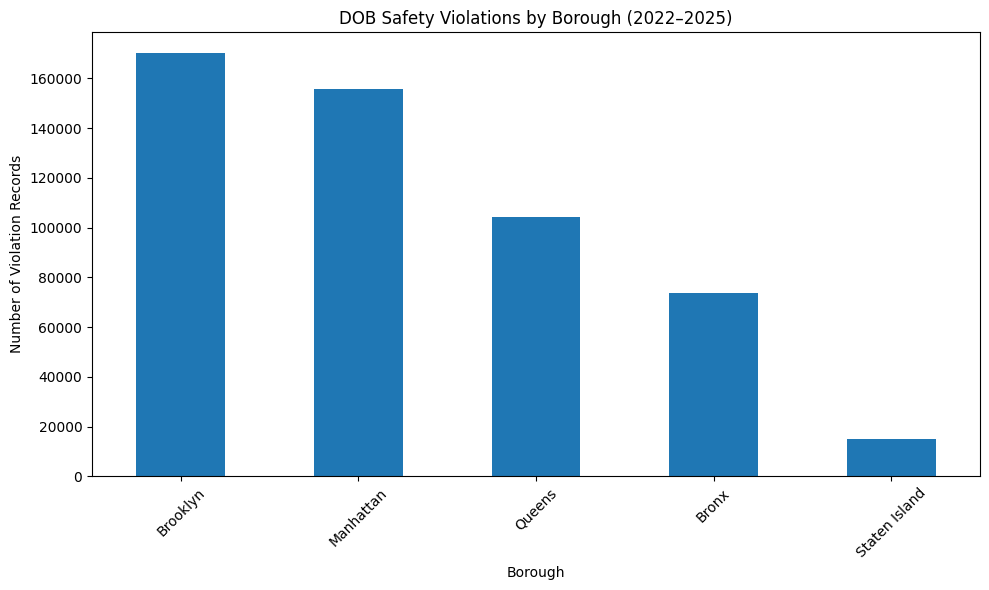

In [ ]:
# ============================================
# 7.1 Violations by Borough
# ============================================

borough_eda = (
    df_housing["borough"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
borough_eda.plot(kind="bar")

plt.title("DOB Safety Violations by Borough (2022–2025)")
plt.xlabel("Borough")
plt.ylabel("Number of Violation Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

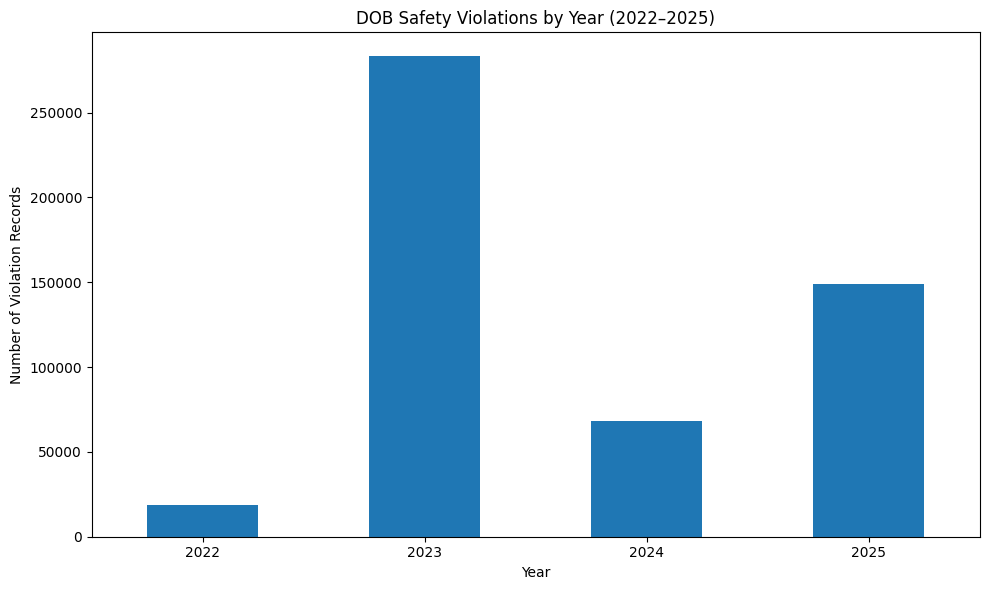

In [ ]:
# ============================================
# 7.2 Violations by Year
# ============================================

year_eda = (
    df_housing["violation_issue_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))
year_eda.plot(kind="bar")

plt.title("DOB Safety Violations by Year (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Number of Violation Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# 7.3 Violations by Borough and Year
# ============================================

df_housing["year"] = df_housing["violation_issue_date"].dt.year

housing_borough_year = (
    df_housing
    .groupby(["year", "borough"])
    .size()
    .reset_index(name="violation_records")
)

display(housing_borough_year)

,year,borough,violation_records
0,2022,Bronx,3628
1,2022,Brooklyn,4957
2,2022,Manhattan,6370
3,2022,Queens,3304
4,2022,Staten Island,574
5,2023,Bronx,37080
6,2023,Brooklyn,88025
7,2023,Manhattan,97513
8,2023,Queens,52393
9,2023,Staten Island,7370


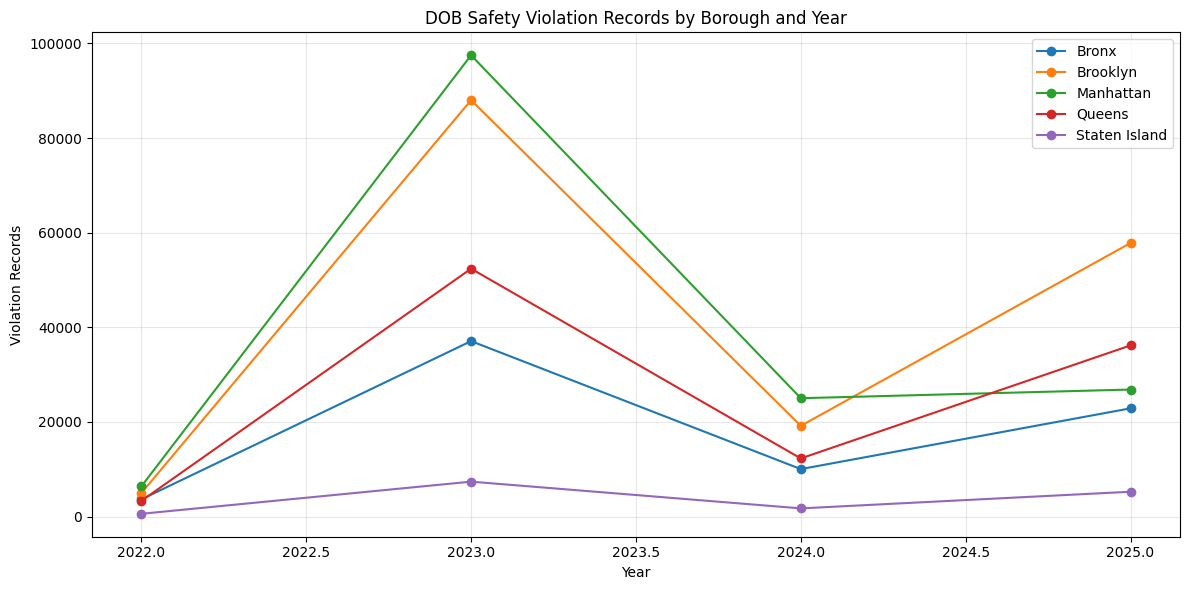

In [ ]:
plt.figure(figsize=(12, 6))

for borough in housing_borough_year["borough"].dropna().unique():
    borough_data = housing_borough_year[
        housing_borough_year["borough"] == borough
    ]

    plt.plot(
        borough_data["year"],
        borough_data["violation_records"],
        marker="o",
        label=borough
    )

plt.title("DOB Safety Violation Records by Borough and Year")
plt.xlabel("Year")
plt.ylabel("Violation Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Pre-Integration Cleaning — DOB Safety Violations

The DOB dataset is cleaned before integration with the transportation dataset.

The cleaning focuses on fields required for the analysis and integration. Records with missing borough values are removed because borough is required to assign each record to a borough-year group. Other missing values are retained when they are not required for the analysis, avoiding unnecessary loss of data.

In [ ]:
# ============================================
# 8. Pre-Integration Cleaning — DOB
# ============================================

# Keep a copy before cleaning
housing_before = len(df_housing)

# Standardize date
df_housing["violation_issue_date"] = pd.to_datetime(
    df_housing["violation_issue_date"],
    errors="coerce"
)

# Standardize borough text
df_housing["borough"] = (
    df_housing["borough"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Remove records with missing essential integration fields
df_housing = df_housing.dropna(
    subset=["borough", "violation_issue_date"]
).copy()

# Keep only the project's analysis period
df_housing = df_housing[
    df_housing["violation_issue_date"].dt.year.between(2022, 2025)
].copy()

# Report cleaning result
housing_after = len(df_housing)
removed = housing_before - housing_after

print(f"Records before cleaning: {housing_before:,}")
print(f"Records after cleaning:  {housing_after:,}")
print(f"Records removed:         {removed:,}")

print("\nRemaining boroughs:")
print(sorted(df_housing["borough"].unique()))

print("\nMissing values in integration fields:")
print(df_housing[["borough", "violation_issue_date"]].isna().sum())

Records before cleaning: 519,337
Records after cleaning:  518,354
Records removed:         983

Remaining boroughs:
['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

Missing values in integration fields:
borough                 0
violation_issue_date    0
dtype: int64


### Cleaning Result

Records with missing borough values were removed because borough is required for the borough-year integration. Missing values in non-essential fields were retained to avoid unnecessary data loss. The cleaned dataset remains within the 2022–2025 analysis period.

## 9. SIRTA Transportation Dataset

The second dataset is **SIRTA Data**, from the Transportation domain.

Dataset ID: `xeqp-qz8h`

The dataset contains records of serious traffic injury incidents in New York City.

As with the DOB dataset, the data will first be inspected and cleaned independently before being aggregated and integrated at the borough-year level.

In [ ]:
# ============================================
# 9.1 Load SIRTA Data
# ============================================

import requests
from urllib3.util.retry import Retry
from requests.adapters import HTTPAdapter
from io import StringIO

sirta_url = "https://data.cityofnewyork.us/resource/xeqp-qz8h.csv?$limit=50000"

# Automatically retry temporary server errors
session = requests.Session()

retry_strategy = Retry(
    total=5,
    backoff_factor=2,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(max_retries=retry_strategy)
session.mount("https://", adapter)
session.mount("http://", adapter)

response = session.get(
    sirta_url,
    timeout=60
)

response.raise_for_status()

df_sirta = pd.read_csv(
    StringIO(response.text),
    low_memory=False
)

print("SIRTA dataset loaded successfully.")
print(f"Rows: {df_sirta.shape[0]:,}")
print(f"Columns: {df_sirta.shape[1]:,}")

SIRTA dataset loaded successfully.
Rows: 13,754
Columns: 23


In [ ]:
# ============================================
# 9.2 Initial SIRTA Inspection
# ============================================

print("Columns:")
print(list(df_sirta.columns))

print("\nData types:")
display(df_sirta.dtypes)

print("\nMissing values:")
sirta_missing = pd.DataFrame({
    "missing_count": df_sirta.isna().sum(),
    "missing_percentage": (df_sirta.isna().mean() * 100).round(2)
})
display(sirta_missing.sort_values("missing_count", ascending=False))

print("\nDuplicate rows:", df_sirta.duplicated().sum())

Columns:
['open_data_crash_id', 'crash_date', 'crash_time', 'crash_police_precinct', 'crash_borough', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'latitude', 'longitude', 'on_street', 'cross_street', 'address', 'highway_reference_marker', 'zipcode', 'similar_fatalities_severe', 'similar_fatalities_all', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020_', 'neighborhood_tabulation_area_nta_2020_']

Data types:


,0
open_data_crash_id,float64
crash_date,object
crash_time,object
crash_police_precinct,float64
crash_borough,object
total_non_severe_injuries,float64
total_severe_injuries,float64
total_fatalities,float64
latitude,float64
longitude,float64



Missing values:


,missing_count,missing_percentage
highway_reference_marker,12702,92.35
address,11177,81.26
bin,10967,79.74
bbl,10967,79.74
census_tract_2020_,9886,71.88
neighborhood_tabulation_area_nta_2020_,9886,71.88
council_district,9883,71.86
community_board,9883,71.86
zipcode,5682,41.31
cross_street,5642,41.02



Duplicate rows: 3


In [ ]:
# ============================================
# 9.3 Date and Borough Checks
# ============================================

df_sirta["crash_date"] = pd.to_datetime(
    df_sirta["crash_date"],
    errors="coerce"
)

print("Date range:")
print(f"Earliest: {df_sirta['crash_date'].min()}")
print(f"Latest:   {df_sirta['crash_date'].max()}")

print("\nBorough distribution:")
display(df_sirta["crash_borough"].value_counts(dropna=False))

Date range:
Earliest: 2022-01-01 00:00:00
Latest:   2026-06-30 00:00:00

Borough distribution:


,count
crash_borough,
Brooklyn,3954
Queens,3282
Manhattan,2733
Bronx,2617
Staten Island,669
NaN,499


## 10. SIRTA Exploratory Analysis and Pre-Integration Cleaning

The SIRTA dataset is filtered to the project's 2022–2025 analysis period.

For integration, the key fields are:
- `crash_date` → year
- `crash_borough` → borough
- `total_non_severe_injuries`
- `total_severe_injuries`
- `total_fatalities`

Duplicate records and records without a borough are removed because they cannot be reliably assigned to a borough-year group. Other fields that are not required for the integration are retained only when useful for later analysis.

In [ ]:
# ============================================
# 10.1 Filter and Clean SIRTA
# ============================================

sirta_before = len(df_sirta)

# Convert date
df_sirta["crash_date"] = pd.to_datetime(
    df_sirta["crash_date"],
    errors="coerce"
)

# Keep only 2022-2025
df_sirta = df_sirta[
    df_sirta["crash_date"].dt.year.between(2022, 2025)
].copy()

# Standardize borough names
df_sirta["crash_borough"] = (
    df_sirta["crash_borough"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Remove exact duplicate records
df_sirta = df_sirta.drop_duplicates().copy()

# Borough is required for integration
df_sirta = df_sirta.dropna(
    subset=["crash_borough"]
).copy()

sirta_after = len(df_sirta)

print(f"Records before cleaning: {sirta_before:,}")
print(f"Records after cleaning:  {sirta_after:,}")
print(f"Records removed:         {sirta_before - sirta_after:,}")

print("\nRemaining boroughs:")
print(sorted(df_sirta["crash_borough"].unique()))

print("\nDate range:")
print(df_sirta["crash_date"].min())
print(df_sirta["crash_date"].max())

Records before cleaning: 13,754
Records after cleaning:  11,922
Records removed:         1,832

Remaining boroughs:
['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

Date range:
2022-01-01 00:00:00
2025-12-30 00:00:00


In [ ]:
# ============================================
# 10.2 SIRTA EDA
# ============================================

df_sirta["year"] = df_sirta["crash_date"].dt.year

sirta_year = df_sirta["year"].value_counts().sort_index()

sirta_borough = df_sirta["crash_borough"].value_counts()

print("Crash records by year:")
display(sirta_year)

print("Crash records by borough:")
display(sirta_borough)

print("Total injuries and fatalities:")
print(
    "Non-severe injuries:",
    df_sirta["total_non_severe_injuries"].sum()
)
print(
    "Severe injuries:",
    df_sirta["total_severe_injuries"].sum()
)
print(
    "Fatalities:",
    df_sirta["total_fatalities"].sum()
)

Crash records by year:


,count
year,
2022,2879
2023,3016
2024,3114
2025,2913


Crash records by borough:


,count
crash_borough,
Brooklyn,3557
Queens,2974
Manhattan,2448
Bronx,2365
Staten Island,578


Total injuries and fatalities:
Non-severe injuries: 3228.0
Severe injuries: 12011.0
Fatalities: 970.0


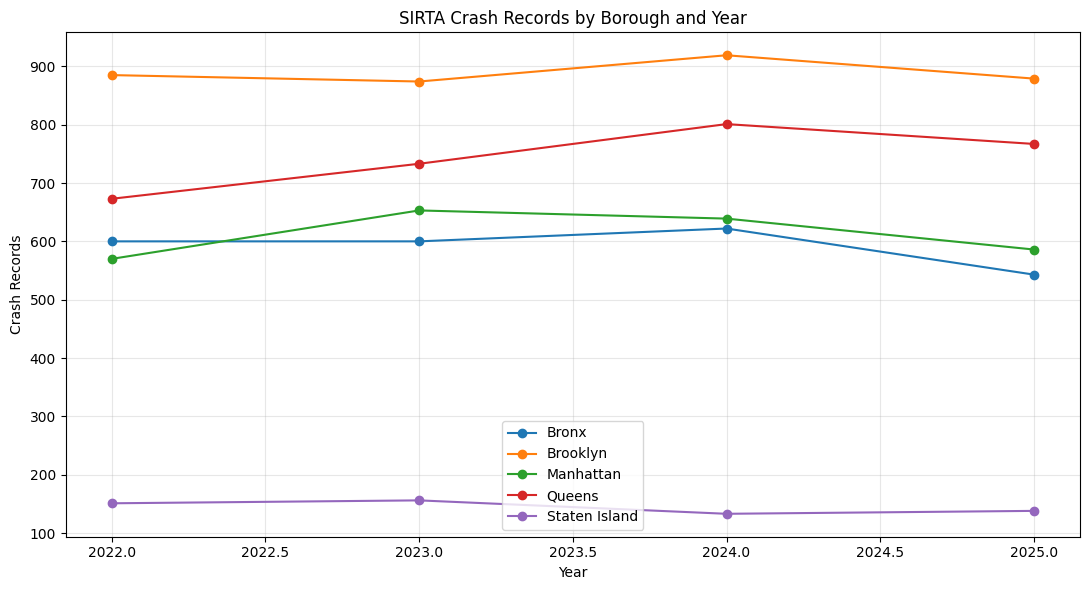

In [ ]:
# ============================================
# 10.3 Crash Records by Borough and Year
# ============================================

sirta_borough_year = (
    df_sirta
    .groupby(["year", "crash_borough"])
    .size()
    .reset_index(name="crash_records")
)

plt.figure(figsize=(11, 6))

for borough in sirta_borough_year["crash_borough"].unique():
    data = sirta_borough_year[
        sirta_borough_year["crash_borough"] == borough
    ]

    plt.plot(
        data["year"],
        data["crash_records"],
        marker="o",
        label=borough
    )

plt.title("SIRTA Crash Records by Borough and Year")
plt.xlabel("Year")
plt.ylabel("Crash Records")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### SIRTA Cleaning Result

The SIRTA dataset was restricted to 2022–2025, duplicate records were removed, and records without a borough were excluded because borough is required for integration. The cleaned data is now ready to be aggregated at the borough-year level.

## 11. Aggregate DOB Data to Borough-Year Level

The DOB records are aggregated by borough and year because the transportation dataset will be aggregated at the same level.

For each borough-year combination, we calculate:
- `violation_records` — number of safety violation records
- `unique_buildings` — number of distinct buildings identified by BIN

Using borough and year as the common granularity allows the two datasets to be integrated without joining individual violation records to individual crash records.

In [ ]:
# ============================================
# 11.1 Aggregate DOB by Borough and Year
# ============================================

dob_aggregated = (
    df_housing
    .groupby(["borough", "year"])
    .agg(
        violation_records=("violation_number", "count"),
        unique_buildings=("bin", "nunique")
    )
    .reset_index()
)

print("DOB borough-year aggregation:")
display(dob_aggregated)

DOB borough-year aggregation:


,borough,year,violation_records,unique_buildings
0,Bronx,2022,3628,2241
1,Bronx,2023,37080,8579
2,Bronx,2024,10024,5188
3,Bronx,2025,22868,18006
4,Brooklyn,2022,4957,2958
5,Brooklyn,2023,88025,22283
6,Brooklyn,2024,19170,11841
7,Brooklyn,2025,57823,49052
8,Manhattan,2022,6370,4075
9,Manhattan,2023,97513,19277


In [ ]:
# ============================================
# 11.2 Validate DOB Borough-Year Aggregation
# ============================================

print(f"Number of borough-year groups: {len(dob_aggregated)}")
print(f"Number of boroughs: {dob_aggregated['borough'].nunique()}")
print(f"Years: {sorted(dob_aggregated['year'].unique())}")

display(dob_aggregated)

Number of borough-year groups: 20
Number of boroughs: 5
Years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


,borough,year,violation_records,unique_buildings
0,Bronx,2022,3628,2241
1,Bronx,2023,37080,8579
2,Bronx,2024,10024,5188
3,Bronx,2025,22868,18006
4,Brooklyn,2022,4957,2958
5,Brooklyn,2023,88025,22283
6,Brooklyn,2024,19170,11841
7,Brooklyn,2025,57823,49052
8,Manhattan,2022,6370,4075
9,Manhattan,2023,97513,19277


## 12. Aggregate SIRTA Data to Borough-Year Level

SIRTA is aggregated to the same borough-year granularity as the DOB dataset. This creates compatible summary data that can be integrated using borough and year.

In [ ]:
# ============================================
# 12.1 Aggregate SIRTA by Borough and Year
# ============================================

df_sirta["crash_date"] = pd.to_datetime(
    df_sirta["crash_date"],
    errors="coerce"
)

# Keep project period
df_sirta = df_sirta[
    df_sirta["crash_date"].dt.year.between(2022, 2025)
].copy()

# Create year
df_sirta["year"] = df_sirta["crash_date"].dt.year

# Standardize borough
df_sirta["crash_borough"] = (
    df_sirta["crash_borough"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Remove records without a borough
df_sirta = df_sirta.dropna(
    subset=["crash_borough"]
).copy()

sirta_aggregated = (
    df_sirta
    .groupby(["crash_borough", "year"])
    .agg(
        crash_records=("open_data_crash_id", "count"),
        non_severe_injuries=("total_non_severe_injuries", "sum"),
        severe_injuries=("total_severe_injuries", "sum"),
        fatalities=("total_fatalities", "sum")
    )
    .reset_index()
    .rename(columns={"crash_borough": "borough"})
)

print("SIRTA borough-year aggregation:")
display(sirta_aggregated)

SIRTA borough-year aggregation:


,borough,year,crash_records,non_severe_injuries,severe_injuries,fatalities
0,Bronx,2022,600,141.0,600.0,55.0
1,Bronx,2023,600,189.0,600.0,46.0
2,Bronx,2024,622,194.0,638.0,52.0
3,Bronx,2025,543,158.0,559.0,33.0
4,Brooklyn,2022,885,228.0,866.0,76.0
5,Brooklyn,2023,874,232.0,871.0,66.0
6,Brooklyn,2024,919,281.0,916.0,65.0
7,Brooklyn,2025,879,220.0,895.0,76.0
8,Manhattan,2022,570,114.0,575.0,40.0
9,Manhattan,2023,653,174.0,654.0,39.0


In [ ]:
# ============================================
# 12.2 Validate SIRTA Aggregation
# ============================================

print(f"Number of borough-year groups: {len(sirta_aggregated)}")
print(f"Number of boroughs: {sirta_aggregated['borough'].nunique()}")
print(f"Years: {sorted(sirta_aggregated['year'].unique())}")

display(sirta_aggregated)

Number of borough-year groups: 20
Number of boroughs: 5
Years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


,borough,year,crash_records,non_severe_injuries,severe_injuries,fatalities
0,Bronx,2022,600,141.0,600.0,55.0
1,Bronx,2023,600,189.0,600.0,46.0
2,Bronx,2024,622,194.0,638.0,52.0
3,Bronx,2025,543,158.0,559.0,33.0
4,Brooklyn,2022,885,228.0,866.0,76.0
5,Brooklyn,2023,874,232.0,871.0,66.0
6,Brooklyn,2024,919,281.0,916.0,65.0
7,Brooklyn,2025,879,220.0,895.0,76.0
8,Manhattan,2022,570,114.0,575.0,40.0
9,Manhattan,2023,653,174.0,654.0,39.0


## 13. Integrate the Two Datasets

The two datasets are integrated at the **borough-year level**.

- `borough` identifies the NYC borough.
- `year` identifies the analysis year.
- These two attributes are common to both datasets.

Aggregating before integration prevents individual violation records from being incorrectly matched with individual crash records. The resulting dataset contains one row for each borough-year combination.

In [ ]:
# ============================================
# 13.1 Integrate DOB and SIRTA
# ============================================

integrated_df = pd.merge(
    dob_aggregated,
    sirta_aggregated,
    on=["borough", "year"],
    how="inner"
)

print("Integrated dataset:")
print(f"Rows: {integrated_df.shape[0]}")
print(f"Columns: {integrated_df.shape[1]}")

display(integrated_df)

Integrated dataset:
Rows: 20
Columns: 8


,borough,year,violation_records,unique_buildings,crash_records,non_severe_injuries,severe_injuries,fatalities
0,Bronx,2022,3628,2241,600,141.0,600.0,55.0
1,Bronx,2023,37080,8579,600,189.0,600.0,46.0
2,Bronx,2024,10024,5188,622,194.0,638.0,52.0
3,Bronx,2025,22868,18006,543,158.0,559.0,33.0
4,Brooklyn,2022,4957,2958,885,228.0,866.0,76.0
5,Brooklyn,2023,88025,22283,874,232.0,871.0,66.0
6,Brooklyn,2024,19170,11841,919,281.0,916.0,65.0
7,Brooklyn,2025,57823,49052,879,220.0,895.0,76.0
8,Manhattan,2022,6370,4075,570,114.0,575.0,40.0
9,Manhattan,2023,97513,19277,653,174.0,654.0,39.0


In [ ]:
# ============================================
# 13.2 Validate Integration
# ============================================

print("Boroughs:")
print(sorted(integrated_df["borough"].unique()))

print("\nYears:")
print(sorted(integrated_df["year"].unique()))

print("\nMissing values:")
display(integrated_df.isnull().sum())

print(
    f"\nExpected borough-year combinations: "
    f"{5 * 4}"
)

print(
    f"Actual borough-year combinations: "
    f"{len(integrated_df)}"
)

Boroughs:
['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']

Years:
[np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

Missing values:


,0
borough,0
year,0
violation_records,0
unique_buildings,0
crash_records,0
non_severe_injuries,0
severe_injuries,0
fatalities,0



Expected borough-year combinations: 20
Actual borough-year combinations: 20


## 14. Post-Integration Cleaning and Final Dataset

The integrated dataset was checked for missing values and duplicate borough-year combinations. Derived measures are added to support the later analysis.

The final dataset contains one row per borough-year combination for 2022–2025.

In [ ]:
# ============================================
# 14.1 Final Cleaning and Derived Measures
# ============================================

# Check for duplicate borough-year combinations
print(
    "Duplicate borough-year combinations:",
    integrated_df.duplicated(
        subset=["borough", "year"]
    ).sum()
)

# Derived measures
integrated_df["total_injuries"] = (
    integrated_df["non_severe_injuries"]
    + integrated_df["severe_injuries"]
)

integrated_df["violations_per_building"] = (
    integrated_df["violation_records"]
    / integrated_df["unique_buildings"]
)

integrated_df["injuries_per_crash"] = (
    integrated_df["total_injuries"]
    / integrated_df["crash_records"]
)

# Final check
print("\nFinal dataset shape:", integrated_df.shape)

print("\nMissing values:")
display(integrated_df.isnull().sum())

display(integrated_df)

Duplicate borough-year combinations: 0

Final dataset shape: (20, 11)

Missing values:


,0
borough,0
year,0
violation_records,0
unique_buildings,0
crash_records,0
non_severe_injuries,0
severe_injuries,0
fatalities,0
total_injuries,0
violations_per_building,0


,borough,year,violation_records,unique_buildings,crash_records,non_severe_injuries,severe_injuries,fatalities,total_injuries,violations_per_building,injuries_per_crash
0,Bronx,2022,3628,2241,600,141.0,600.0,55.0,741.0,1.618920,1.235000
1,Bronx,2023,37080,8579,600,189.0,600.0,46.0,789.0,4.322182,1.315000
2,Bronx,2024,10024,5188,622,194.0,638.0,52.0,832.0,1.932151,1.337621
3,Bronx,2025,22868,18006,543,158.0,559.0,33.0,717.0,1.270021,1.320442
4,Brooklyn,2022,4957,2958,885,228.0,866.0,76.0,1094.0,1.675794,1.236158
5,Brooklyn,2023,88025,22283,874,232.0,871.0,66.0,1103.0,3.950321,1.262014
6,Brooklyn,2024,19170,11841,919,281.0,916.0,65.0,1197.0,1.618951,1.302503
7,Brooklyn,2025,57823,49052,879,220.0,895.0,76.0,1115.0,1.178810,1.268487
8,Manhattan,2022,6370,4075,570,114.0,575.0,40.0,689.0,1.563190,1.208772
9,Manhattan,2023,97513,19277,653,174.0,654.0,39.0,828.0,5.058515,1.267994


In [ ]:
# ============================================
# 14.2 Export Final Integrated Dataset
# ============================================

integrated_df.to_csv(
    "integrated.csv",
    index=False
)

print("Final integrated dataset saved as integrated.csv")

Final integrated dataset saved as integrated.csv


In [ ]:
# ============================================
# 14.3 Final Validation
# ============================================

print("Final validation")
print("----------------")
print(f"Rows: {integrated_df.shape[0]}")
print(f"Columns: {integrated_df.shape[1]}")
print(f"Unique boroughs: {integrated_df['borough'].nunique()}")
print(f"Years: {sorted(integrated_df['year'].unique())}")
print(
    "Duplicate borough-year groups:",
    integrated_df.duplicated(
        subset=["borough", "year"]
    ).sum()
)
print(
    "Total missing values:",
    integrated_df.isnull().sum().sum()
)

Final validation
----------------
Rows: 20
Columns: 11
Unique boroughs: 5
Years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Duplicate borough-year groups: 0
Total missing values: 0


## 15. Research Questions and Visualizations

The integrated dataset contains building-safety and transportation-safety measures at the borough-year level.

Because the project requires each research question to investigate a meaningful relationship between the two chosen datasets, the analysis focuses on cross-domain relationships rather than standalone counts.

The five-member team contributes 10 research questions and 10 visualizations, with two research questions and two visualizations assigned to each member.

### Research Questions

**RQ1.** Do borough-years with more building safety violations also have more serious injury crashes?

**RQ2.** Do borough-years with more unique buildings also experience more serious injury crashes?

**RQ3.** Is higher building violation intensity associated with more fatalities?

**RQ4.** Is higher building violation intensity associated with more severe injuries per crash?

**RQ5.** Is the number of building violations associated with the total number of injuries from serious crashes?

**RQ6.** Do years with larger changes in building violations also show changes in serious injury crashes?

**RQ7.** Do boroughs with greater growth in unique buildings from 2022 to 2025 also experience greater growth in crash records?

**RQ8.** Is higher building violation intensity associated with a higher fatality rate per crash?

**RQ9.** Is higher building violation intensity associated with a greater share of severe injuries among total injuries?

**RQ10.** Which borough-year combinations experience both high building-safety pressure and high transportation-safety burden?

In [ ]:
# ============================================
# 15.1 Additional Analysis Metrics
# ============================================

integrated_df["fatalities_per_crash"] = (
    integrated_df["fatalities"]
    / integrated_df["crash_records"]
)

integrated_df["severe_injury_share"] = (
    integrated_df["severe_injuries"]
    / integrated_df["total_injuries"]
)

# Avoid infinite values in case of zero denominators
integrated_df = integrated_df.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Additional analysis metrics created.")
display(
    integrated_df[
        [
            "borough",
            "year",
            "violations_per_building",
            "injuries_per_crash",
            "fatalities_per_crash",
            "severe_injury_share"
        ]
    ]
)

Additional analysis metrics created.


,borough,year,violations_per_building,injuries_per_crash,fatalities_per_crash,severe_injury_share
0,Bronx,2022,1.618920,1.235000,0.091667,0.809717
1,Bronx,2023,4.322182,1.315000,0.076667,0.760456
2,Bronx,2024,1.932151,1.337621,0.083601,0.766827
3,Bronx,2025,1.270021,1.320442,0.060773,0.779637
4,Brooklyn,2022,1.675794,1.236158,0.085876,0.791590
5,Brooklyn,2023,3.950321,1.262014,0.075515,0.789665
6,Brooklyn,2024,1.618951,1.302503,0.070729,0.765246
7,Brooklyn,2025,1.178810,1.268487,0.086462,0.802691
8,Manhattan,2022,1.563190,1.208772,0.070175,0.834543
9,Manhattan,2023,5.058515,1.267994,0.059724,0.789855


In [ ]:
import plotly.express as px

# Work on a copy of the integrated dataset
df = integrated_df.copy()

# Derived measures
df["total_injuries"] = (
    df["non_severe_injuries"] + df["severe_injuries"]
)

df["violations_per_building"] = (
    df["violation_records"] / df["unique_buildings"]
)

df["crashes_per_building"] = (
    df["crash_records"] / df["unique_buildings"]
)

df["injuries_per_crash"] = (
    df["total_injuries"] / df["crash_records"]
)

print("Visualization dataset ready.")

Visualization dataset ready.


In [ ]:
fig = px.scatter(
    df,
    x="violation_records",
    y="crash_records",
    color="borough",
    hover_data=["year"],
    title="Building Safety Violations vs. Crash Records",
    labels={
        "violation_records": "Violation Records",
        "crash_records": "Crash Records"
    }
)

fig.show()

In [ ]:
fig = px.scatter(
    df,
    x="violation_records",
    y="total_injuries",
    color="borough",
    hover_data=["year"],
    title="Building Safety Violations vs. Total Injuries",
    labels={
        "violation_records": "Violation Records",
        "total_injuries": "Total Injuries"
    }
)

fig.show()

In [ ]:
fig = px.scatter(
    df,
    x="violation_records",
    y="severe_injuries",
    color="borough",
    hover_data=["year"],
    title="Building Safety Violations vs. Severe Injuries",
    labels={
        "violation_records": "Violation Records",
        "severe_injuries": "Severe Injuries"
    }
)

fig.show()

In [ ]:
fig = px.scatter(
    df,
    x="violation_records",
    y="fatalities",
    color="borough",
    hover_data=["year"],
    title="Building Safety Violations vs. Crash Fatalities",
    labels={
        "violation_records": "Violation Records",
        "fatalities": "Fatalities"
    }
)

fig.show()

In [ ]:
borough_summary = (
    df.groupby("borough")[["violation_records", "crash_records"]]
      .sum()
      .reset_index()
)

# Normalize each measure so they can be compared
borough_summary["violations_index"] = (
    borough_summary["violation_records"] /
    borough_summary["violation_records"].max() * 100
)

borough_summary["crashes_index"] = (
    borough_summary["crash_records"] /
    borough_summary["crash_records"].max() * 100
)

plot_df = borough_summary[
    ["borough", "violations_index", "crashes_index"]
].melt(
    id_vars="borough",
    var_name="measure",
    value_name="index"
)

fig = px.bar(
    plot_df,
    x="borough",
    y="index",
    color="measure",
    barmode="group",
    title="Building Violations and Crash Records by Borough",
    labels={
        "borough": "Borough",
        "index": "Relative Index (Maximum = 100)",
        "measure": "Measure"
    }
)

fig.show()

In [ ]:
heatmap_data = df.pivot(
    index="borough",
    columns="year",
    values="violations_per_building"
)

fig = px.imshow(
    heatmap_data,
    text_auto=".2f",
    aspect="auto",
    title="Violation Intensity per Building by Borough and Year",
    labels={
        "x": "Year",
        "y": "Borough",
        "color": "Violations per Building"
    }
)

fig.show()

In [ ]:
yearly = (
    df.groupby("year")[["violation_records", "crash_records"]]
      .sum()
      .reset_index()
)

yearly["violations_index"] = (
    yearly["violation_records"] /
    yearly["violation_records"].iloc[0] * 100
)

yearly["crashes_index"] = (
    yearly["crash_records"] /
    yearly["crash_records"].iloc[0] * 100
)

plot_df = yearly[
    ["year", "violations_index", "crashes_index"]
].melt(
    id_vars="year",
    var_name="measure",
    value_name="index"
)

fig = px.line(
    plot_df,
    x="year",
    y="index",
    color="measure",
    markers=True,
    title="Change in Building Violations and Crash Records Over Time",
    labels={
        "year": "Year",
        "index": "Relative Index (2022 = 100)",
        "measure": "Measure"
    }
)

fig.show()

In [ ]:
df["violation_intensity_group"] = pd.qcut(
    df["violations_per_building"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

injury_group = (
    df.groupby("violation_intensity_group", observed=True)
      .agg(
          severe_injuries=("severe_injuries", "sum"),
          fatalities=("fatalities", "sum")
      )
      .reset_index()
)

plot_df = injury_group.melt(
    id_vars="violation_intensity_group",
    var_name="outcome",
    value_name="count"
)

fig = px.bar(
    plot_df,
    x="violation_intensity_group",
    y="count",
    color="outcome",
    barmode="group",
    title="Crash Severity by Building Violation Intensity",
    labels={
        "violation_intensity_group": "Violation Intensity",
        "count": "Number of Cases",
        "outcome": "Crash Outcome"
    }
)

fig.show()

In [ ]:
borough_injuries = (
    df.groupby("borough")[
        ["non_severe_injuries", "severe_injuries"]
    ]
    .sum()
    .reset_index()
)

plot_df = borough_injuries.melt(
    id_vars="borough",
    var_name="injury_type",
    value_name="injuries"
)

fig = px.bar(
    plot_df,
    x="borough",
    y="injuries",
    color="injury_type",
    barmode="stack",
    title="Crash Injuries by Borough",
    labels={
        "borough": "Borough",
        "injuries": "Number of Injuries",
        "injury_type": "Injury Type"
    }
)

fig.show()

In [ ]:
plot_df = df.copy()

plot_df["violations_index"] = (
    plot_df.groupby("borough")["violation_records"]
           .transform(lambda x: x / x.iloc[0] * 100)
)

plot_df["crashes_index"] = (
    plot_df.groupby("borough")["crash_records"]
           .transform(lambda x: x / x.iloc[0] * 100)
)

# Create a long-format dataframe
violations_line = plot_df[
    ["borough", "year", "violations_index"]
].rename(columns={"violations_index": "index"})

violations_line["measure"] = "Building Violations"

crashes_line = plot_df[
    ["borough", "year", "crashes_index"]
].rename(columns={"crashes_index": "index"})

crashes_line["measure"] = "Crash Records"

line_data = pd.concat(
    [violations_line, crashes_line],
    ignore_index=True
)

fig = px.line(
    line_data,
    x="year",
    y="index",
    color="measure",
    facet_col="borough",
    markers=True,
    title="Building Violations and Crash Trends by Borough",
    labels={
        "year": "Year",
        "index": "Relative Index (First Year = 100)",
        "measure": "Measure"
    }
)

fig.for_each_annotation(
    lambda a: a.update(text=a.text.replace("borough=", ""))
)

fig.show()

## Main Findings

**RQ1 — Building Violation Records:**  
Violation records varied strongly across boroughs and years, with a noticeable peak in 2023. Brooklyn and Manhattan generally recorded the highest values.

**RQ2 — Unique Buildings:**  
The number of unique buildings also varied across boroughs, with substantial increases in 2025 for several boroughs, especially Brooklyn and Queens.

**RQ3 — Crash Records:**  
Brooklyn generally recorded the highest number of crash records, while Staten Island had the lowest. Crash levels also changed across the four years.

**RQ4 — Severe Injuries:**  
Severe injuries were generally highest in Brooklyn and Queens, while Staten Island consistently had the lowest numbers.

**RQ5 — Non-Severe Injuries:**  
Non-severe injuries varied across both boroughs and years. Brooklyn and Queens generally showed higher values than Staten Island.

**RQ6 — Fatalities:**  
Brooklyn and Queens recorded the highest fatality counts in several years, while Staten Island had substantially fewer fatalities.

**RQ7 — Violations vs. Crashes:**  
The comparison shows a relationship between building violation records and crash records across borough-year observations. This is an association and does not establish that violations cause crashes.

**RQ8 — Buildings vs. Crashes:**  
The number of unique buildings shows variation alongside crash records. Borough-year observations with more buildings do not necessarily have the highest crash counts.

**RQ9 — Violation Intensity vs. Fatalities:**  
Violation intensity, measured as violations per unique building, varies across borough-year observations and can be compared with fatalities. The relationship should be interpreted as descriptive rather than causal.

**RQ10 — Violations vs. Total Injuries:**  
Building violation records and total injuries show differences across borough-year observations. This provides a direct comparison between the housing-safety and transportation-safety domains, but does not demonstrate causation.

## EDA, Cleaning & Integration Summary

### Exploratory Data Analysis
Both datasets were examined using row/column counts, data types, missing-value counts, duplicate checks, date ranges, and borough distributions. The analysis confirmed that both datasets contain relevant geographic and temporal attributes, allowing them to be compared at the borough-year level.

### Pre-Integration Cleaning
- Date fields were converted to a consistent datetime format and invalid dates were checked.
- Borough values were standardized so that both datasets use the same five NYC borough names.
- Duplicate records were identified and removed where necessary.
- Missing values were reviewed based on their importance to the analysis. Fields required for aggregation and integration were retained only when valid, while non-essential missing attributes were not artificially imputed.
- Numeric measures such as injuries and fatalities were checked for invalid values and consistency.

### Aggregation & Integration
The datasets have different record-level granularities, so individual records were not directly joined. Instead, both datasets were aggregated by **borough and year**.

For the DOB Safety Violations dataset, we calculated:
- Total violation records
- Number of unique buildings

For the SIRTA dataset, we calculated:
- Total crash records
- Non-severe injuries
- Severe injuries
- Fatalities

The two aggregated datasets were then integrated using **borough + year** as the common key. This produced **20 records representing 5 boroughs across 2022–2025**. This granularity was selected because both datasets contain borough and date information and it provides a consistent level for cross-domain comparison.

### Post-Integration Validation
The integrated dataset was checked for missing values, duplicate borough-year combinations, expected boroughs, expected years, and data types. All **20 expected borough-year combinations** were present and the final integrated dataset contained no missing values in its analysis fields.

### Analysis Note
The resulting relationships describe associations between building-safety and transportation-safety measures. They should not be interpreted as evidence that one factor directly causes another.

## 16. Dataset Links

Both datasets come from [NYC Open Data](https://opendata.cityofnewyork.us/).

| Domain | Dataset | Dataset ID | Dataset page | API endpoint used in this notebook |
|---|---|---|---|---|
| Housing & Development | DOB Safety Violations | `855j-jady` | https://data.cityofnewyork.us/d/855j-jady | `https://data.cityofnewyork.us/resource/855j-jady.csv` (filtered to 2022–2025 with `$where`, see Section 4.1) |
| Transportation | SIRTA Data | `xeqp-qz8h` | https://data.cityofnewyork.us/d/xeqp-qz8h | `https://data.cityofnewyork.us/resource/xeqp-qz8h.csv?$limit=50000` (see Section 9.1) |

Project code, website and documentation: https://github.com/MahaGad/Data-Engineering-Project1

## 17. Prompts Used

AI assistants were used during the project. The full prompt log, organized by team member, is in [`AI_prompts.md`](https://github.com/MahaGad/Data-Engineering-Project1/blob/main/AI_prompts.md) in the GitHub repository.

| Member | Role | Prompts documented in |
|---|---|---|
| 1 | Data analysis & coordination | `AI_prompts.md` → Member 1 |
| 2 | Website structure & filters | `AI_prompts.md` → Member 2 |
| 3 | Interactive visualizations | `AI_prompts.md` → Member 3 |
| 4 | Research questions, findings & story | `AI_prompts.md` → Member 4 |
| 5 | GitHub, testing, README & deployment | `AI_prompts.md` → Member 5 |